# Course 2: Ten Years of Deep Learning Ideas
## Session 9: Flow matching, rectified flow and fast generation

**Goal:** train a flow-matching model on the same 2-D data as session 8, sample it with 1 to 32 Euler steps, and measure how reflow and minibatch optimal-transport pairing straighten its paths.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. Setup: the same data and distance as session 8
Same 2-D swiss roll, same sliced Wasserstein distance (SWD) and the same noise floor, so the numbers here can be compared with session 8.

In [1]:
import math, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.datasets import make_swiss_roll

torch.set_num_threads(1)                    # small models run fastest on one thread
torch.manual_seed(0); np.random.seed(0)

def swiss_roll_2d(n, seed):
    X, _ = make_swiss_roll(n_samples=n, noise=0.5, random_state=seed)
    return (X[:, [0, 2]] / 7.0).astype(np.float32)

def swd(a, b, n_proj=500, seed=0):
    rng = np.random.default_rng(seed); th = rng.standard_normal((2, n_proj)); th /= np.linalg.norm(th, axis=0)
    pa, pb = np.sort(np.asarray(a) @ th, axis=0), np.sort(np.asarray(b) @ th, axis=0)
    return float(np.sqrt(((pa - pb) ** 2).mean()))

Xtrain = torch.from_numpy(swiss_roll_2d(20000, 0)); Xtest = swiss_roll_2d(2000, 1)
floor = np.mean([swd(swiss_roll_2d(2000, s), Xtest) for s in [2, 3, 4]])
print(f"noise floor: SWD between two real samples of 2,000 points = {floor:.3f}")

class Net(nn.Module):                       # the same network as session 8: x and time features in, 2 numbers out
    def __init__(self, h=128, n_freq=8):
        super().__init__()
        self.register_buffer("freqs", torch.exp(torch.linspace(0, math.log(200), n_freq)))
        self.net = nn.Sequential(nn.Linear(2 + 2 * n_freq, h), nn.SiLU(), nn.Linear(h, h), nn.SiLU(),
                                 nn.Linear(h, h), nn.SiLU(), nn.Linear(h, 2))
    def forward(self, x, t):                # t in [0, 1]
        a = t[:, None] * self.freqs[None]
        return self.net(torch.cat([x, torch.sin(a), torch.cos(a)], 1))

noise floor: SWD between two real samples of 2,000 points = 0.046


### 2. Flow matching: regression onto a velocity
Pick noise $x_0 \sim N(0, I)$, a data point $x_1$ and a time $t \in [0, 1]$. The point $x_t = (1 - t)\,x_0 + t\,x_1$ moves on a straight line with constant velocity $x_1 - x_0$. Train a network to predict that velocity:

$L = \mathbb{E}\, \| v_\theta(x_t, t) - (x_1 - x_0) \|^2$

There is no ODE to solve during training, only a regression. The best possible $v_\theta(x, t)$ is the *average* of $x_1 - x_0$ over all pairs whose line passes through $x$ at time $t$, and following this averaged field from noise reproduces the data distribution (Lipman et al. 2023; Liu et al. 2023; Albergo & Vanden-Eijnden 2023). `pairs` lets later sections train on chosen pairs instead of random ones.

In [2]:
def train_fm(steps=5000, B=512, lr=2e-3, seed=0, pairs=None, init=None):
    torch.manual_seed(seed); model = Net()
    if init is not None: model.load_state_dict(init.state_dict())
    opt = torch.optim.Adam(model.parameters(), lr=lr); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for step in range(steps):
        if pairs is None:                                       # independent pairs: random noise, random data
            x1 = Xtrain[torch.randint(0, len(Xtrain), (B,))]; x0 = torch.randn_like(x1)
        else:                                                   # chosen pairs (sections 5 and 6)
            i = torch.randint(0, len(pairs[0]), (B,)); x0, x1 = pairs[0][i], pairs[1][i]
        t = torch.rand(B)
        xt = (1 - t[:, None]) * x0 + t[:, None] * x1
        loss = F.mse_loss(model(xt, t), x1 - x0)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return model

@torch.no_grad()
def euler(model, x0, n_steps, keep_path=False):
    x, path = x0.clone(), [x0.clone()]
    for k in range(n_steps):
        t = torch.full((len(x),), k / n_steps)
        x = x + model(x, t) / n_steps                           # one Euler step of dx/dt = v(x, t)
        if keep_path: path.append(x.clone())
    return (x, torch.stack(path)) if keep_path else x

t0 = time.time(); fm = train_fm()
print(f"flow-matching model trained in {time.time() - t0:.0f}s")

STEPS = [1, 2, 4, 8, 32]
def score(model, n_steps):                                       # mean SWD over three noise seeds
    return np.mean([swd(euler(model, torch.randn(2000, 2, generator=torch.Generator().manual_seed(s)), n_steps).numpy(), Xtest) for s in range(3)])
res = {"flow matching": [score(fm, n) for n in STEPS]}
for n, v in zip(STEPS, res["flow matching"]): print(f"flow matching, {n:2d} Euler steps: SWD {v:.3f}")

flow-matching model trained in 16s


flow matching,  1 Euler steps: SWD 0.952
flow matching,  2 Euler steps: SWD 0.437
flow matching,  4 Euler steps: SWD 0.219
flow matching,  8 Euler steps: SWD 0.118
flow matching, 32 Euler steps: SWD 0.063


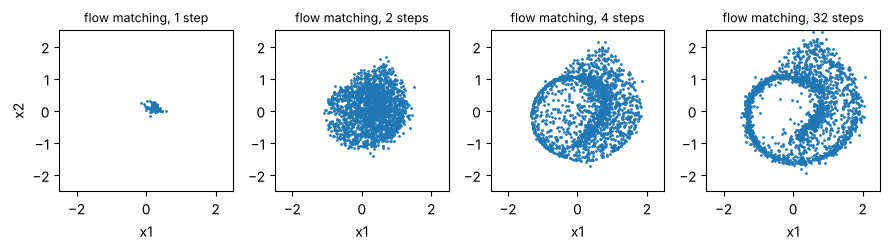

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(9, 2.6))
z = torch.randn(2000, 2, generator=torch.Generator().manual_seed(0))
for a, n in zip(ax, [1, 2, 4, 32]):
    xs = euler(fm, z, n).numpy()
    a.scatter(xs[:, 0], xs[:, 1], s=1); a.set_title(f"flow matching, {n} step{'s' if n > 1 else ''}", fontsize=9)
    a.set_xlim(-2.5, 2.5); a.set_ylim(-2.5, 2.5); a.set_xlabel("x1")
ax[0].set_ylabel("x2"); plt.tight_layout(); plt.show()

### 3. A DDPM trained here, for comparison
The same network and the same number of training steps, trained as in session 8 (noise prediction, $T = 100$, linear schedule) and sampled with deterministic DDIM, so both models use one network evaluation per step.

In [4]:
T = 100
betas = torch.linspace(1e-3, 0.2, T); abar = torch.cat([torch.ones(1), torch.cumprod(1 - betas, 0)])

def train_ddpm(steps=5000, B=512, lr=2e-3, seed=0):
    torch.manual_seed(seed); model = Net()
    opt = torch.optim.Adam(model.parameters(), lr=lr); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for step in range(steps):
        x0 = Xtrain[torch.randint(0, len(Xtrain), (B,))]; t = torch.randint(1, T + 1, (B,)); eps = torch.randn_like(x0)
        xt = abar[t].sqrt()[:, None] * x0 + (1 - abar[t]).sqrt()[:, None] * eps
        loss = F.mse_loss(model(xt, t / T), eps)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    return model

@torch.no_grad()
def ddim(model, x, n_steps):
    ts = torch.linspace(T, 0, n_steps + 1).round().long()
    for t, s in zip(ts[:-1], ts[1:]):
        eps = model(x, torch.full((len(x),), t.item() / T))
        x0_hat = (x - (1 - abar[t]).sqrt() * eps) / abar[t].sqrt()
        x = abar[s].sqrt() * x0_hat + (1 - abar[s]).sqrt() * eps
    return x

t0 = time.time(); ddpm = train_ddpm()
print(f"DDPM trained in {time.time() - t0:.0f}s")
res["DDPM + DDIM sampler"] = [np.mean([swd(ddim(ddpm, torch.randn(2000, 2, generator=torch.Generator().manual_seed(s)), n).numpy(), Xtest) for s in range(3)]) for n in STEPS]
print("steps   flow matching   DDPM + DDIM")
for k, n in enumerate(STEPS): print(f"{n:5d}   {res['flow matching'][k]:13.3f}   {res['DDPM + DDIM sampler'][k]:11.3f}")

DDPM trained in 15s


steps   flow matching   DDPM + DDIM
    1           0.952         6.775
    2           0.437         0.640
    4           0.219         0.484
    8           0.118         0.233
   32           0.063         0.091


### 4. Why are many steps needed? The paths curve
Each training pair moves in a straight line, but lines from different pairs cross, and the network can only learn their average at each crossing point. So the learned paths bend, and one big Euler step misses. A simple measure of straightness: simulate 2,000 paths with 100 small steps, then divide their total length by the total straight-line distance between their two ends (1.0 means perfectly straight).

In [5]:
def straightness(model, n=2000, n_steps=100, seed=0):
    z = torch.randn(n, 2, generator=torch.Generator().manual_seed(seed))
    end, path = euler(model, z, n_steps, keep_path=True)
    length = (path[1:] - path[:-1]).norm(dim=2).sum(0)              # length of each simulated path
    return (length.sum() / (end - z).norm(dim=1).sum()).item()
print(f"flow matching, independent pairs: path length / end-to-end distance = {straightness(fm):.3f}")

flow matching, independent pairs: path length / end-to-end distance = 2.049


### 5. Reflow: straighten the paths with the model's own pairs
Rectified flow (Liu et al. 2023) runs the trained model from many noise points to get pairs (noise, generated point), then trains again on those pairs. The new pairs are linked by the model's own paths, which do not cross, so the regression targets disagree less and the new paths are straighter. Here we generate 20,000 pairs with 100 Euler steps and fine-tune the first model on them for 3,000 steps.

In [6]:
t0 = time.time()
z_pairs = torch.randn(20000, 2, generator=torch.Generator().manual_seed(11))
x_pairs = euler(fm, z_pairs, 100)
reflow = train_fm(steps=3000, pairs=(z_pairs, x_pairs), init=fm, seed=1)
print(f"reflow pairs generated and model fine-tuned in {time.time() - t0:.0f}s")
res["reflow (2-rectified)"] = [score(reflow, n) for n in STEPS]
print(f"straightness: first model {straightness(fm):.3f}, after one reflow {straightness(reflow):.3f}")

reflow pairs generated and model fine-tuned in 14s


straightness: first model 2.049, after one reflow 1.001


### 6. Minibatch optimal-transport pairs
Tong et al. 2024 pair noise and data *inside each batch* so that the total squared distance is as small as possible (an assignment problem, solved here with `scipy.optimize.linear_sum_assignment`). Close pairs cross less, so even the first model has straighter paths and no reflow is needed. To save time we compute the pairs once, in blocks of 256, instead of for every batch as in the paper.

In [7]:
t0 = time.time(); rng = np.random.default_rng(12); x0_ot, x1_ot = [], []
for block in range(80):                                          # 80 blocks x 256 = 20,480 pairs
    x1 = Xtrain[rng.choice(len(Xtrain), 256, replace=False)]; x0 = torch.from_numpy(rng.standard_normal((256, 2)).astype(np.float32))
    rows, cols = linear_sum_assignment(torch.cdist(x0, x1).pow(2).numpy())   # minimize total squared distance
    x0_ot.append(x0[rows]); x1_ot.append(x1[cols])
ot_pairs = (torch.cat(x0_ot), torch.cat(x1_ot))
mean_sq = lambda a, b: (a - b).pow(2).sum(1).mean().item()
x1_rand = Xtrain[torch.randint(0, len(Xtrain), (len(ot_pairs[0]),))]
print(f"mean squared distance within a pair: random pairing {mean_sq(ot_pairs[0], x1_rand):.2f}, OT pairing {mean_sq(*ot_pairs):.2f}")
ot = train_fm(pairs=ot_pairs, seed=2)
print(f"OT pairs computed and model trained in {time.time() - t0:.0f}s")
res["minibatch OT pairs"] = [score(ot, n) for n in STEPS]
print(f"straightness: OT-paired model {straightness(ot):.3f}")

mean squared distance within a pair: random pairing 3.97, OT pairing 0.32


OT pairs computed and model trained in 16s


straightness: OT-paired model 1.005


### 7. All four models side by side

steps           flow matching     DDPM + DDIM sampler    reflow (2-rectified)      minibatch OT pairs
    1                   0.952                   6.775                   0.058                   0.060
    2                   0.437                   0.640                   0.057                   0.050
    4                   0.219                   0.484                   0.057                   0.049
    8                   0.118                   0.233                   0.057                   0.050
   32                   0.063                   0.091                   0.057                   0.050
noise floor 0.046


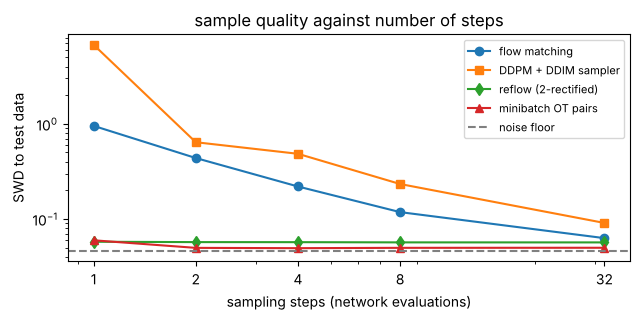

In [8]:
print("steps  " + "  ".join(f"{k:>22s}" for k in res))
for i, n in enumerate(STEPS):
    print(f"{n:5d}  " + "  ".join(f"{res[k][i]:22.3f}" for k in res))
print(f"noise floor {floor:.3f}")

plt.figure(figsize=(6.5, 3.3))
for k, mk in zip(res, "osd^"):
    plt.plot(STEPS, res[k], marker=mk, label=k)
plt.axhline(floor, color="gray", ls="--", label="noise floor")
plt.xscale("log"); plt.yscale("log"); plt.xticks(STEPS, [str(s) for s in STEPS])
plt.xlabel("sampling steps (network evaluations)"); plt.ylabel("SWD to test data"); plt.title("sample quality against number of steps")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

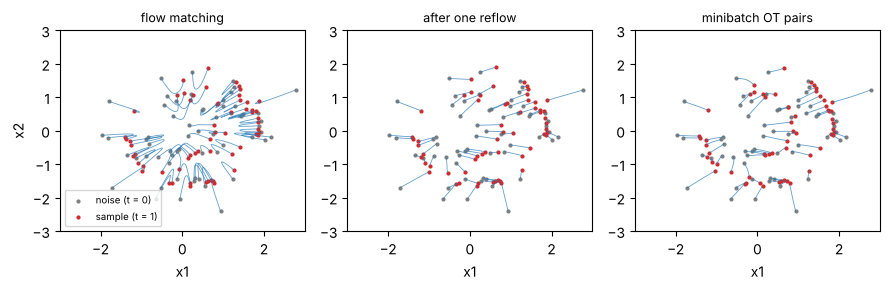

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
z = torch.randn(60, 2, generator=torch.Generator().manual_seed(5))
for a, (name, m) in zip(ax, [("flow matching", fm), ("after one reflow", reflow), ("minibatch OT pairs", ot)]):
    end, path = euler(m, z, 32, keep_path=True)
    for j in range(len(z)): a.plot(path[:, j, 0], path[:, j, 1], lw=0.6, color="C0", alpha=0.7)
    a.scatter(z[:, 0], z[:, 1], s=4, color="gray", label="noise (t = 0)"); a.scatter(end[:, 0], end[:, 1], s=4, color="C3", label="sample (t = 1)")
    a.set_title(name, fontsize=9); a.set_xlim(-3, 3); a.set_ylim(-3, 3); a.set_xlabel("x1")
ax[0].set_ylabel("x2"); ax[0].legend(fontsize=7, loc="lower left"); plt.tight_layout(); plt.show()

### 8. Rectified flow at scale (NOT RUN here)
Stable Diffusion 3 is a rectified-flow transformer (Esser et al. 2024). Its default sampler in `diffusers` is an Euler solver for the flow ODE, the same idea as `euler` above.

In [ ]:
# NOT RUN: needs a GPU, `pip install diffusers transformers accelerate sentencepiece` and a Hugging Face account (the model is gated behind a licence and is a download of about 15 GB)
import torch
from diffusers import StableDiffusion3Pipeline
pipe = StableDiffusion3Pipeline.from_pretrained("stabilityai/stable-diffusion-3-medium-diffusers", torch_dtype=torch.float16).to("cuda")
print(type(pipe.scheduler).__name__)          # FlowMatchEulerDiscreteScheduler
for steps in [4, 8, 28]:
    image = pipe("a red bicycle leaning on a green wall", num_inference_steps=steps, guidance_scale=7.0,
                 generator=torch.Generator("cuda").manual_seed(0)).images[0]
    image.save(f"bicycle_{steps}_steps.png")
# Compare the three images: what breaks first when the number of steps falls?

### 9. Exercises

In [10]:
# TODO: Heun's method. Write heun(model, x0, n_steps): an Euler step to get a trial point, then average the
# velocities at the start and at the trial point. It costs two network evaluations per step, so compare it
# with Euler at the same number of evaluations (Heun with 4 steps against Euler with 8) for the first model.
def heun(model, x0, n_steps):
    return None          # replace with your code

out = heun(fm, torch.randn(2000, 2), 4)
print("not done yet" if out is None else f"Heun, 4 steps (8 evaluations): SWD {swd(out.numpy(), Xtest):.3f}")

not done yet


In [11]:
# TODO: a second reflow. Generate new pairs with the reflow model, fine-tune again, and report the
# straightness and the 1-step SWD of the 3-rectified flow. Does a second round still help?
def second_reflow():
    return None          # replace with your code: return (straightness, one_step_swd)

r = second_reflow()
print("not done yet" if r is None else f"3-rectified flow: straightness {r[0]:.3f}, 1-step SWD {r[1]:.3f}")

not done yet


### What to notice
(Written from the run above; your numbers will match if you keep the seeds.)

1. **Plain flow matching needs many steps.** Its SWD was 0.952 with 1 Euler step, 0.437 with 2, 0.219 with 4, 0.118 with 8 and 0.063 with 32 (noise floor 0.046). With one step every sample lands near the data mean: at $t = 0$ the noise says nothing about its partner, so the best velocity is $\mathbb{E}[x_1] - x_0$, and $x_0 + v$ is the mean.
2. **The DDPM trained here, sampled with DDIM, was worse at every step count**: 6.775 at 1 step, 0.640 at 2, 0.233 at 8 and 0.091 at 32. This compares one diffusion setup (noise prediction, linear schedule) with one flow-matching setup, using the same network and training budget; it is not a general verdict on the two families. The 1-step failure comes from dividing by $\sqrt{\bar\alpha_T} \approx 0.0045$ in $\hat x_0$.
3. **The paths were curved, and both fixes straightened them.** Path length divided by end-to-end distance was 2.049 for plain flow matching, 1.001 after one reflow and 1.005 with minibatch OT pairs (1.0 is a straight line). The trajectory plot shows the same.
4. **Reflow made one step almost as good as many**: SWD 0.058 at 1 step, against 0.952 before reflow. More steps did not help it (0.057), because it can only be as good as the pairs it was trained on, which came from the first model.
5. **Minibatch OT pairing** cut the average squared distance within a training pair from 3.97 to 0.32 and gave 0.060 at 1 step and 0.049 to 0.050 at 2 to 32 steps, better than plain flow matching at 32 steps. In 2-D a block of 256 points covers the distribution well; do not expect gains this large in high dimensions, where a batch covers the distribution far more thinly.
6. All of this is 2-D with a small network; it shows the mechanics of straight paths, not their size at image scale.